# RutaPro · Notebook 05: Cold start sin trampa

**Problema que corrige.** En el notebook 03 los estudiantes "nuevos" eran estudiantes que **sí participaron en el entrenamiento**: sus inscripciones pasadas ayudaron a formar los vectores de los cursos y la popularidad. Un estudiante realmente nuevo nunca aportó nada, así que ese experimento era optimista.

**Protocolo de este notebook (validación cruzada por estudiantes):**
1. Se parten los 133 estudiantes evaluables en **5 pliegues**.
2. En cada pliegue, los estudiantes del pliegue quedan **fuera de TODO el entrenamiento** (ni sus inscripciones, ni embeddings, ni popularidad, ni vecinos). Los modelos se entrenan con entrenamiento + validación de los demás.
3. A esos estudiantes se les recomienda **solo con su formulario de registro**. Se evalúan **dos protocolos**, porque responden preguntas distintas:
   - **A. Estudiante nuevo realista.** El estudiante no tiene ningún historial, así que todo lo que se inscriba es el objetivo (todas sus inscripciones, unas 7 por estudiante) y no hay cursos que excluir. Mide el desempeño absoluto de un estudiante nuevo. Sus cifras **no son comparables** con las del notebook 03 (hay más inscripciones por acertar) y no tiene oráculo, porque el techo del simulador solo está definido paso a paso.
   - **B. Comparación directa con el protocolo con historial.** Mismos estudiantes, mismas inscripciones de prueba y **mismos candidatos** (se excluyen los cursos que el estudiante ya había tomado, como en el notebook 03), pero el modelo se entrenó **sin** sus datos. Aísla cuánto aporta el historial: la única diferencia con el notebook 03 es que el estudiante no participó en el entrenamiento.
4. Además se mide **cuántas preguntas necesita el formulario**: se repite con formularios reducidos.

Estrategias comparadas (todas usan solo el formulario): popularidad filtrada por reglas (respaldo v1), popularidad por segmento, contenido por perfil declarado y LightFM solo con atributos, con y sin reglas.

In [1]:
import os, sys, subprocess
from google.colab import drive

NECESITA_LIGHTFM = True

# 1) Conectar el Drive y entrar a la carpeta del proyecto
drive.mount('/content/drive')
PROY = "/content/drive/MyDrive/RutaPro"
os.chdir(PROY + "/02_Notebooks")
print("Carpeta actual:", os.getcwd())

# 2) Comprobar que están los archivos imprescindibles
faltan = [f for f in ["rutapro_rec.py", "rutapro_sim.py", "rutapro_extra.py", "rutapro_mooc.py",
                      "resultados/hiperparametros.json", "../01_Datos/cursos.csv",
                      "../01_Datos/pares_usuario_curso.csv"] if not os.path.exists(f)]
print("Archivos que faltan:", faltan if faltan else "ninguno, todo en su sitio")

# 3) LightFM: usa la copia compilada en el Drive; si no existe, la compila (≈ 2 min) y la guarda
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stdout[-1500:], r.stderr[-1500:])
        raise RuntimeError("Falló: " + cmd[:70])

if NECESITA_LIGHTFM:
    LF = PROY + "/lightfm_src"
    if not os.path.exists(LF + "/lightfm"):
        print("Compilando LightFM, un momento...")
        sh("pip install -q cython")
        sh("rm -rf /content/lightfm_src && git clone -q --depth 1 https://github.com/lyst/lightfm.git /content/lightfm_src")
        p = "/content/lightfm_src/setup.py"
        s = open(p).read()
        s = s.replace("compiler_directives={'language_level' : \"3\"}",
                      "compiler_directives={'language_level': \"3\", 'legacy_implicit_noexcept': True}").replace("-march=native", "-O2")
        open(p, "w").write(s)
        sh("cd /content/lightfm_src && python setup.py cythonize -q && python setup.py build_ext --inplace -q")
        sh("rm -rf '" + LF + "' && cp -r /content/lightfm_src '" + LF + "'")
    sys.path.insert(0, LF)
    import lightfm
    print("LightFM", lightfm.__version__)

Mounted at /content/drive
Carpeta actual: /content/drive/.shortcut-targets-by-id/1Z5XbASVfSPtFWsbbN2qhK0vGCB8tiPaJ/RutaPro/02_Notebooks
Archivos que faltan: ninguno, todo en su sitio
LightFM 1.17


In [2]:
try:
    import lightfm
    print("LightFM", lightfm.__version__)
except ImportError as e:
    raise SystemExit("Falta LightFM: instala con 'conda install -c conda-forge lightfm' (ver 02_Notebooks/README).") from e

LightFM 1.17


In [3]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")

import rutapro_rec as rr
import rutapro_sim as sim
import rutapro_extra as ex

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#9a9890"
TXT, TXT2 = "#0b0b0b", "#52514e"
mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#d4d3cd", "axes.labelcolor": TXT2, "xtick.color": TXT2, "ytick.color": TXT2,
    "text.color": TXT, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "axes.axisbelow": True, "font.size": 10, "figure.dpi": 110,
})
BASE = rr.ruta_base()
DATA = BASE / "01_Datos"
FIG = BASE / "04_Informe" / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
RES = BASE / "02_Notebooks" / "resultados_robustez"; RES.mkdir(parents=True, exist_ok=True)
def guardar(fig, n): fig.savefig(FIG / f"{n}.png", dpi=160, bbox_inches="tight")

H = json.loads((BASE / "02_Notebooks" / "resultados" / "hiperparametros.json").read_text())
cursos, usuarios, pares = rr.cargar_datos()
perfil_de = usuarios.set_index("user_id").to_dict("index")
prueba = rr.construir_particion(cursos, usuarios, pares, etapa="prueba")
eleg = prueba.usuarios_elegibles()
_, _, traza = sim.generar_dataset(cursos, sim.ParamsSim(), con_traza=True)      # solo para el oráculo

# Segmento del baseline: el elegido en validación en el notebook 04 (misma regla de parsimonia)
g = pd.read_csv(RES / "grid_popularidad_segmento.csv")
mejor = g[g.ndcg >= g.ndcg.max() - 0.01].sort_values(["n_cols", "m"]).iloc[0]
COLS, M = tuple(mejor.segmento.split(" + ")), float(mejor.m)
print(f"Estudiantes evaluables: {len(eleg)} | baseline por segmento: {COLS}, m = {M}")

Estudiantes evaluables: 133 | baseline por segmento: ('objetivo_laboral',), m = 0.0


## 1. Validación cruzada con estudiantes retenidos

In [4]:
SEMILLAS = [42, 43, 44, 45, 46]
folds = ex.pliegues_usuarios(eleg, n_pliegues=5, seed=0)
print("Tamaño de cada pliegue:", [len(f) for f in folds])
hc = H["Contenido (TF-IDF)"]
FORM = {                      # formularios: qué campos conoce el sistema
    "completo": ("carrera", "nivel", "idioma", "objetivo", "ciclo", "interes", "domina"),
    "sin intereses ni dominio": ("carrera", "nivel", "idioma", "objetivo", "ciclo"),
    "3 preguntas (objetivo, nivel, idioma)": ("objetivo", "nivel", "idioma"),
    "solo objetivo laboral": ("objetivo",),
}
DET = {"A": {}, "B": {}}       # protocolo -> nombre -> detalle por estudiante
acum = {"A": {}, "B": {}}      # protocolo -> nombre -> (lista por pliegue) o {semilla: lista}
reg = lambda s_, p: rr.aplicar_reglas(s_, cursos, p)

def evaluar_cs(modelo, d_eval, fuera):
    return rr.evaluar(modelo, d_eval, ks=(5, 10), usuarios=sorted(fuera), devolver_detalle=True)[1]

for k, fuera in enumerate(folds):
    d_fit = ex.particion_cold_start(cursos, usuarios, pares, fuera, objetivo="test")      # entrenamiento SIN los retenidos
    d_eval = {"A": ex.particion_cold_start(cursos, usuarios, pares, fuera, objetivo="todo"),   # nuevo realista
              "B": prueba}                                                                      # mismos candidatos que el notebook 03
    assert not (set(d_fit.train.user_id) & fuera), "fuga: un estudiante retenido aparece en el entrenamiento"
    pop_s = rr.Popularidad().fit(d_fit).puntajes(None)
    seg = ex.PopularidadSegmento(COLS, M).fit(d_fit)
    cont = rr.ContenidoTFIDF(ngram=tuple(hc["ngram"]), alpha_perfil=hc["alpha_perfil"], usar_vistas=hc["usar_vistas"]).fit(d_fit)
    modelos = {
        "Popularidad + reglas (respaldo v1)": ex.SoloPerfil(lambda p: reg(pop_s, p), perfil_de),
        "Pop. por segmento (sin reglas)": ex.SoloPerfil(seg.puntajes_perfil, perfil_de),
        "Pop. por segmento + reglas": ex.SoloPerfil(lambda p: reg(seg.puntajes_perfil(p), p), perfil_de),
        "Contenido por perfil declarado": ex.SoloPerfil(cont.puntajes_perfil, perfil_de),
        "Contenido por perfil + reglas": ex.SoloPerfil(lambda p: reg(cont.puntajes_perfil(p), p), perfil_de),
    }
    for pr in ("A", "B"):
        modelos_pr = dict(modelos)
        if pr == "B":      # el oráculo solo está bien definido con el mismo objetivo que el protocolo con historial
            modelos_pr["Oráculo (techo)"] = ex.Oraculo(traza).fit(d_eval[pr])
        for n, m in modelos_pr.items():
            acum[pr].setdefault(n, []).append(evaluar_cs(m, d_eval[pr], fuera))
    for sd in SEMILLAS:
        lfm = rr.LightFMHibrido(**H["LightFM híbrido"], seed=sd).fit(d_fit)
        if k == 0 and sd == SEMILLAS[0]:     # comprobación: con todos los campos == puntajes_perfil de LightFMHibrido
            u0 = sorted(fuera)[0]
            assert np.allclose(ex.puntajes_cold_filtrado(lfm, perfil_de[u0]), lfm.puntajes_perfil(perfil_de[u0]))
        variantes = {
            "LightFM solo atributos (sin reglas)": lambda p: ex.puntajes_cold_filtrado(lfm, p, FORM["completo"]),
            "LightFM solo atributos + reglas · formulario completo":
                lambda p: reg(ex.puntajes_cold_filtrado(lfm, p, FORM["completo"]), p),
            "LightFM + reglas · sin intereses ni dominio":
                lambda p: reg(ex.puntajes_cold_filtrado(lfm, p, FORM["sin intereses ni dominio"]), p),
            "LightFM + reglas · 3 preguntas":
                lambda p: reg(ex.puntajes_cold_filtrado(lfm, p, FORM["3 preguntas (objetivo, nivel, idioma)"]), p),
            "LightFM · solo objetivo laboral":
                lambda p: ex.puntajes_cold_filtrado(lfm, p, FORM["solo objetivo laboral"]),
        }
        for pr in ("A", "B"):
            for n, fn in variantes.items():
                acum[pr].setdefault(n, {}).setdefault(sd, []).append(evaluar_cs(ex.SoloPerfil(fn, perfil_de), d_eval[pr], fuera))
    print(f"pliegue {k + 1}/{len(folds)} listo")

for pr in ("A", "B"):
    for n, v in acum[pr].items():
        DET[pr][n] = ex.promediar_det([pd.concat(x) for x in v.values()]) if isinstance(v, dict) else pd.concat(v)
print("Estudiantes por modelo:", {len(v.user_id.unique()) for pr in DET.values() for v in pr.values()})

Tamaño de cada pliegue: [27, 27, 27, 26, 26]
pliegue 1/5 listo
pliegue 2/5 listo
pliegue 3/5 listo
pliegue 4/5 listo
pliegue 5/5 listo
Estudiantes por modelo: {133}


## 2. Resultados

Para el protocolo **B** se agrega la referencia: **LightFM + reglas CON historial** (notebook 03), sobre los mismos estudiantes y los mismos candidatos.

In [5]:
fab_lfm = lambda s: rr.LightFMHibrido(**H["LightFM híbrido"], seed=s)
DET["B"]["Referencia: LightFM + reglas CON historial"], _ = ex.evaluar_semillas(
    fab_lfm, prueba, semillas=SEMILLAS, envolver=lambda m: ex.ConReglas(m, cursos, perfil_de))

orden_cs = ["Popularidad + reglas (respaldo v1)", "Pop. por segmento (sin reglas)", "Pop. por segmento + reglas",
            "Contenido por perfil declarado", "Contenido por perfil + reglas",
            "LightFM solo atributos (sin reglas)", "LightFM solo atributos + reglas · formulario completo",
            "LightFM + reglas · sin intereses ni dominio", "LightFM + reglas · 3 preguntas", "LightFM · solo objetivo laboral",
            "Referencia: LightFM + reglas CON historial", "Oráculo (techo)"]
dets_cs = {pr: {n: DET[pr][n] for n in orden_cs if n in DET[pr]} for pr in ("A", "B")}
def tabla_cs(pr, K):
    t = ex.tabla_con_ic(dets_cs[pr], K=K)
    cols = ["estudiantes", "ndcg", "ndcg IC95", "hit_rate", "hit_rate IC95", "recall", "precision"]
    if "Oráculo (techo)" in t.index:
        t["% del techo (NDCG)"] = 100 * t["ndcg"] / t.loc["Oráculo (techo)", "ndcg"]
        cols.append("% del techo (NDCG)")
    return t[cols]
for pr, tit in [("A", "A. Estudiante nuevo realista (objetivo: todas sus inscripciones; sin exclusiones)"),
                ("B", "B. Comparación directa (mismos candidatos y objetivos que el notebook 03)")]:
    for K in (10, 5):
        t = tabla_cs(pr, K); t.to_csv(RES / f"cold_start_{pr}_k{K}.csv")
        print(f"{tit} · K = {K}"); display(t.round(3))

A. Estudiante nuevo realista (objetivo: todas sus inscripciones; sin exclusiones) · K = 10


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95,recall,precision
modelo,,,,,,,
Popularidad + reglas (respaldo v1),133,0.244,"[0.214, 0.276]",0.805,"[0.737, 0.872]",0.257,0.183
Pop. por segmento (sin reglas),133,0.305,"[0.273, 0.338]",0.902,"[0.850, 0.947]",0.301,0.211
Pop. por segmento + reglas,133,0.317,"[0.285, 0.349]",0.910,"[0.857, 0.955]",0.304,0.214
Contenido por perfil declarado,133,0.266,"[0.234, 0.299]",0.872,"[0.812, 0.925]",0.278,0.188
Contenido por perfil + reglas,133,0.308,"[0.273, 0.345]",0.872,"[0.812, 0.925]",0.327,0.221
LightFM solo atributos (sin reglas),133,0.335,"[0.301, 0.367]",0.929,"[0.887, 0.964]",0.339,0.233
LightFM solo atributos + reglas · formulario completo,133,0.341,"[0.306, 0.373]",0.929,"[0.886, 0.965]",0.345,0.237
LightFM + reglas · sin intereses ni dominio,133,0.310,"[0.277, 0.341]",0.899,"[0.848, 0.944]",0.319,0.217
LightFM + reglas · 3 preguntas,133,0.305,"[0.273, 0.336]",0.929,"[0.886, 0.967]",0.321,0.215


A. Estudiante nuevo realista (objetivo: todas sus inscripciones; sin exclusiones) · K = 5


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95,recall,precision
modelo,,,,,,,
Popularidad + reglas (respaldo v1),133,0.234,"[0.199, 0.272]",0.684,"[0.609, 0.759]",0.167,0.238
Pop. por segmento (sin reglas),133,0.292,"[0.254, 0.332]",0.767,"[0.692, 0.835]",0.182,0.262
Pop. por segmento + reglas,133,0.309,"[0.270, 0.348]",0.789,"[0.714, 0.857]",0.193,0.274
Contenido por perfil declarado,133,0.237,"[0.200, 0.276]",0.699,"[0.617, 0.774]",0.162,0.212
Contenido por perfil + reglas,133,0.266,"[0.228, 0.308]",0.722,"[0.647, 0.797]",0.178,0.239
LightFM solo atributos (sin reglas),133,0.317,"[0.276, 0.357]",0.786,"[0.717, 0.850]",0.203,0.287
LightFM solo atributos + reglas · formulario completo,133,0.320,"[0.279, 0.361]",0.789,"[0.720, 0.853]",0.206,0.290
LightFM + reglas · sin intereses ni dominio,133,0.280,"[0.243, 0.316]",0.759,"[0.690, 0.826]",0.190,0.251
LightFM + reglas · 3 preguntas,133,0.285,"[0.246, 0.323]",0.764,"[0.693, 0.827]",0.203,0.267


B. Comparación directa (mismos candidatos y objetivos que el notebook 03) · K = 10


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95,recall,precision,% del techo (NDCG)
modelo,,,,,,,,
Popularidad + reglas (respaldo v1),133,0.132,"[0.095, 0.170]",0.323,"[0.248, 0.398]",0.247,0.037,44.917
Pop. por segmento (sin reglas),133,0.163,"[0.122, 0.207]",0.398,"[0.316, 0.481]",0.303,0.044,55.400
Pop. por segmento + reglas,133,0.168,"[0.126, 0.214]",0.383,"[0.301, 0.466]",0.301,0.044,57.323
Contenido por perfil declarado,133,0.124,"[0.091, 0.159]",0.331,"[0.256, 0.414]",0.240,0.034,42.276
Contenido por perfil + reglas,133,0.162,"[0.126, 0.201]",0.406,"[0.323, 0.489]",0.313,0.044,55.245
LightFM solo atributos (sin reglas),133,0.173,"[0.132, 0.216]",0.412,"[0.331, 0.496]",0.323,0.047,58.949
LightFM solo atributos + reglas · formulario completo,133,0.173,"[0.131, 0.216]",0.412,"[0.331, 0.496]",0.324,0.046,58.808
LightFM + reglas · sin intereses ni dominio,133,0.145,"[0.106, 0.186]",0.349,"[0.272, 0.426]",0.269,0.038,49.252
LightFM + reglas · 3 preguntas,133,0.148,"[0.111, 0.186]",0.380,"[0.304, 0.459]",0.294,0.042,50.259


B. Comparación directa (mismos candidatos y objetivos que el notebook 03) · K = 5


,estudiantes,ndcg,ndcg IC95,hit_rate,hit_rate IC95,recall,precision,% del techo (NDCG)
modelo,,,,,,,,
Popularidad + reglas (respaldo v1),133,0.094,"[0.059, 0.131]",0.195,"[0.128, 0.263]",0.142,0.042,39.930
Pop. por segmento (sin reglas),133,0.109,"[0.070, 0.152]",0.203,"[0.135, 0.278]",0.149,0.044,46.164
Pop. por segmento + reglas,133,0.128,"[0.086, 0.173]",0.241,"[0.165, 0.316]",0.190,0.051,54.294
Contenido por perfil declarado,133,0.089,"[0.058, 0.124]",0.203,"[0.135, 0.271]",0.142,0.041,37.933
Contenido por perfil + reglas,133,0.114,"[0.079, 0.152]",0.248,"[0.180, 0.323]",0.175,0.051,48.554
LightFM solo atributos (sin reglas),133,0.119,"[0.081, 0.160]",0.232,"[0.164, 0.301]",0.168,0.051,50.374
LightFM solo atributos + reglas · formulario completo,133,0.119,"[0.081, 0.160]",0.235,"[0.168, 0.304]",0.168,0.051,50.458
LightFM + reglas · sin intereses ni dominio,133,0.102,"[0.065, 0.143]",0.197,"[0.134, 0.263]",0.147,0.042,43.351
LightFM + reglas · 3 preguntas,133,0.097,"[0.063, 0.134]",0.215,"[0.150, 0.286]",0.149,0.043,41.084


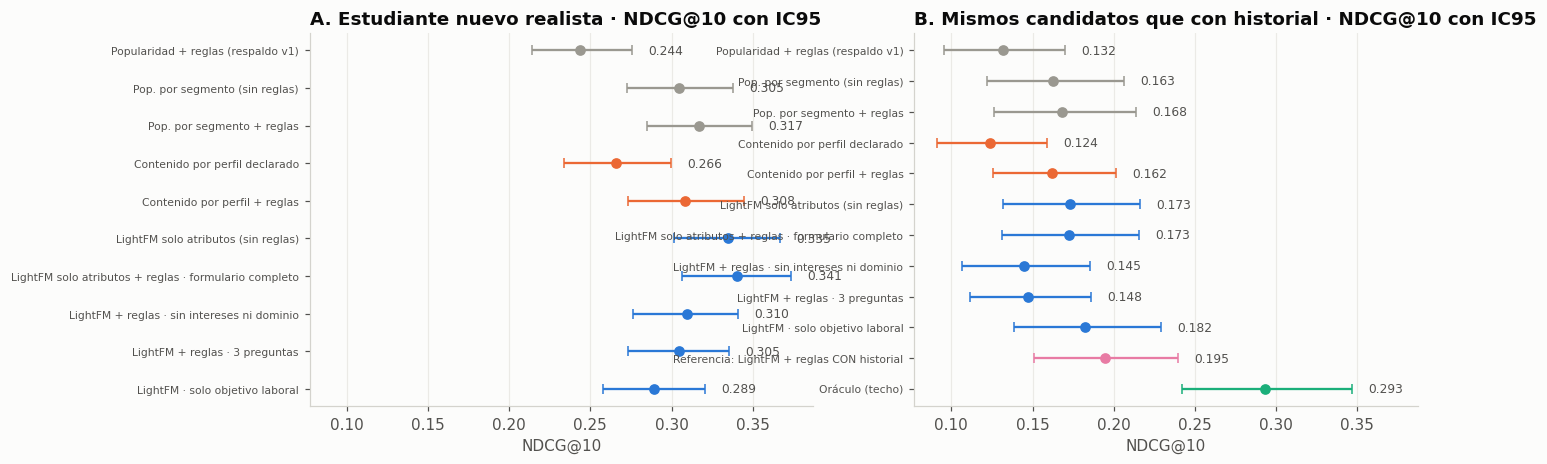

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharex=True)
for ax, pr, tit in zip(axes, ["A", "B"], ["A. Estudiante nuevo realista", "B. Mismos candidatos que con historial"]):
    nombres = list(dets_cs[pr]); y = np.arange(len(nombres))[::-1]
    for yi, n in zip(y, nombres):
        mu, lo, hi = ex.ic_bootstrap(dets_cs[pr][n].query("K == 10")["ndcg"].values)
        col = AQUA if n.startswith("Oráculo") else (MAGENTA if n.startswith("Referencia") else (AZUL if "LightFM" in n else (NARANJA if "Contenido" in n else GRIS)))
        ax.errorbar(mu, yi, xerr=[[mu - lo], [hi - mu]], fmt="o", color=col, ecolor=col, capsize=3, ms=6)
        ax.text(hi + 0.01, yi, f"{mu:.3f}", va="center", fontsize=8, color=TXT2)
    ax.set_yticks(y, nombres, fontsize=7); ax.set_title(f"{tit} · NDCG@10 con IC95"); ax.set_xlabel("NDCG@10"); ax.grid(axis="y", visible=False)
guardar(fig, "22_cold_start_sin_trampa"); plt.show()

**Interpretación.**

**Primero, una corrección importante al notebook 03.** Allí se reportó que un estudiante nuevo obtenía el mismo NDCG@10 que uno con historial (0.189 frente a 0.189). Ese experimento dejaba a los estudiantes "nuevos" **dentro del entrenamiento**, así que sus inscripciones habían moldeado los vectores de los cursos. Con estudiantes realmente fuera del entrenamiento (protocolo B, mismos candidatos y mismos objetivos), LightFM solo con formulario + reglas obtiene **0.173** de NDCG@10 (IC95 de 0.131 a 0.216) frente a **0.195** con historial: cerca del 89 % del desempeño con historial en K = 10. En K = 5 la proporción baja a cerca del 77 % (0.119 frente a 0.154). Es una pérdida real pero moderada, y no la igualdad que se afirmaba.

**Protocolo A (estudiante nuevo realista).** Las cifras absolutas son más altas porque el objetivo incluye todas sus inscripciones (unas 7 por estudiante) y no son comparables con las del notebook 03. Con el formulario completo, LightFM + reglas obtiene NDCG@10 = **0.341** y Hit Rate@10 = **92.9 %**, frente a **0.244 y 80.5 %** del respaldo de popularidad filtrada que usa la app si falta el modelo. La popularidad por segmento + reglas obtiene 0.317 (91.0 %) y el contenido + reglas 0.308.

**Lectura conjunta.**
- Casi todo el beneficio sobre el respaldo viene de **usar el formulario**, sea con el algoritmo que sea (+0.097 de LightFM, +0.073 del baseline por segmento y +0.065 del contenido + reglas en el protocolo A).
- En el protocolo B, LightFM (0.173) y la popularidad por segmento + reglas (0.168) quedan prácticamente empatados.
- **Reglas:** no cambian a LightFM (0.173 con y sin reglas, porque sus atributos ya incluyen idioma y nivel), pero sí al contenido (0.124 a 0.162), que por sí solo ignora el idioma.
- **Cuántas preguntas necesita el formulario.** Los formularios reducidos no dan una conclusión limpia: sin intereses ni dominio 0.145, con 3 preguntas 0.148, solo objetivo laboral 0.182 y completo 0.173. La falta de monotonía (el formulario más corto no es el peor) y el solapamiento de los IC95 indican que estas diferencias están dentro del ruido. Una hipótesis, no verificada, es que al promediar los embeddings de más atributos se diluye el peso del objetivo laboral, que es el factor más importante en el simulador. **No se puede afirmar que el formulario completo sea necesario ni que sobre.**

## 3. Pruebas pareadas

Con corrección de Holm dentro de cada familia, para K = 10 y K = 5:
- **A1.** (protocolo A) ¿La estrategia adoptada supera al respaldo de popularidad filtrada y al baseline por segmento?
- **B1.** (protocolo B) ¿Cuánto pierde un estudiante nuevo frente al mismo modelo **con historial**? Es la medida directa de lo que aporta el historial.

In [7]:
ADOP = "LightFM solo atributos + reglas · formulario completo"
def fam(pr, base, cands, K=10):
    t = pd.DataFrame({n: ex.comparar_pareado(dets_cs[pr][n], dets_cs[pr][base], K=K) for n in cands}).T
    t["p ajustado (Holm)"] = ex.holm(t["p (Wilcoxon)"].astype(float))
    t["¿significativo al 5 %?"] = np.where(t["p ajustado (Holm)"] < 0.05, "sí", "no")
    return t
res_p = {}
for K in (10, 5):
    res_p[f"A1 frente al respaldo v1 · K={K}"] = fam("A", "Popularidad + reglas (respaldo v1)",
        [ADOP, "Pop. por segmento + reglas", "Contenido por perfil + reglas"], K)
    res_p[f"A2 frente a Pop. por segmento + reglas · K={K}"] = fam("A", "Pop. por segmento + reglas",
        [ADOP, "Contenido por perfil + reglas", "LightFM · solo objetivo laboral"], K)
    res_p[f"B1 frente a la referencia CON historial · K={K}"] = fam("B", "Referencia: LightFM + reglas CON historial",
        [ADOP, "LightFM + reglas · 3 preguntas", "LightFM · solo objetivo laboral", "Pop. por segmento + reglas"], K)
    res_p[f"B2 frente a Pop. por segmento + reglas · K={K}"] = fam("B", "Pop. por segmento + reglas",
        [ADOP, "Contenido por perfil + reglas"], K)
for nombre, t in res_p.items():
    t.to_csv(RES / ("cold_start_pruebas_" + nombre.split(" ")[0] + f"_k{nombre.split('=')[-1]}.csv"))
    print(nombre); display(t.round(4))

A1 frente al respaldo v1 · K=10


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
LightFM solo atributos + reglas · formulario completo,0.0969,0.0665,0.1286,86.0,42.0,0.0000,0.0000,sí
Pop. por segmento + reglas,0.0731,0.0395,0.1081,76.0,49.0,0.0003,0.0006,sí
Contenido por perfil + reglas,0.0645,0.0188,0.1110,74.0,51.0,0.0118,0.0118,sí


A2 frente a Pop. por segmento + reglas · K=10


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
LightFM solo atributos + reglas · formulario completo,0.0239,0.0020,0.0453,74.0,54.0,0.0272,0.0543,no
Contenido por perfil + reglas,-0.0085,-0.0483,0.0308,57.0,71.0,0.6310,0.6310,no
LightFM · solo objetivo laboral,-0.0276,-0.0518,-0.0035,49.0,77.0,0.0128,0.0384,sí


B1 frente a la referencia CON historial · K=10


...

,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
LightFM solo atributos + reglas · formulario completo,0.0118,-0.0191,0.0405,56.0,55.0,0.4295,0.4295,no
Contenido por perfil + reglas,-0.0422,-0.0865,0.0029,43.0,73.0,0.0910,0.1820,no
LightFM · solo objetivo laboral,-0.0332,-0.0624,-0.0026,45.0,65.0,0.0233,0.0700,no


B1 frente a la referencia CON historial · K=5


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
LightFM solo atributos + reglas · formulario completo,-0.0352,-0.0628,-0.0095,17.0,33.0,0.0160,0.0480,sí
LightFM + reglas · 3 preguntas,-0.0573,-0.0880,-0.0275,13.0,37.0,0.0002,0.0010,sí
LightFM · solo objetivo laboral,-0.0187,-0.0613,0.0226,26.0,33.0,0.5260,0.5260,no
Pop. por segmento + reglas,-0.0262,-0.0638,0.0126,22.0,30.0,0.1489,0.2977,no


B2 frente a Pop. por segmento + reglas · K=5


,dif. media,IC95 inf,IC95 sup,mejora,empeora,p (Wilcoxon),p ajustado (Holm),¿significativo al 5 %?
LightFM solo atributos + reglas · formulario completo,-0.0090,-0.0457,0.0262,25.0,19.0,0.8109,1.0,no
Contenido por perfil + reglas,-0.0135,-0.0598,0.0311,22.0,22.0,0.6403,1.0,no


**Interpretación.**

**A. Estudiante nuevo realista.**
- LightFM + reglas supera al respaldo de popularidad filtrada por **+0.097** de NDCG@10 (IC95 de +0.067 a +0.129; p ajustado < 0.001; mejora a 86 estudiantes y empeora a 42), y también con K = 5 (+0.086, significativo). La popularidad por segmento + reglas (+0.073; p ajustado = 0.0006) y el contenido + reglas (+0.065; p ajustado = 0.012) también lo superan en K = 10.
- Frente a la **popularidad por segmento + reglas**, LightFM mejora en +0.024 (IC95 de +0.002 a +0.045; p sin ajustar = 0.027), pero tras la corrección de Holm el p ajustado es **0.054**, por lo que no es significativo. En K = 5 la diferencia es +0.012 (no significativa). El formulario con solo el objetivo laboral queda por debajo del baseline por segmento + reglas (−0.028; p ajustado = 0.038), lo que muestra que parte de la ventaja viene de las reglas de idioma y nivel y del resto de campos.

**B. Comparación directa con el modelo con historial.**
- Lo que se pierde por no tener historial: −0.022 en K = 10 (IC95 de −0.049 a +0.004; p ajustado = 0.48, no significativo) y **−0.035 en K = 5** (IC95 de −0.063 a −0.010; p ajustado = 0.048, significativo). El historial sí aporta, sobre todo en las primeras posiciones de la lista.
- El formulario de 3 preguntas queda significativamente por debajo del modelo con historial (−0.047 en K = 10 con p ajustado = 0.022; −0.057 en K = 5 con p ajustado = 0.001).
- Frente a la popularidad por segmento + reglas, LightFM sin historial no se distingue (+0.004 en K = 10; −0.009 en K = 5; p ajustado = 1.0).

## 4. Ejemplo cualitativo: un estudiante nuevo

El mismo perfil que se usa en el notebook 02 y en la demostración de la app, pero comparando las dos estrategias que resultaron mejores.

In [8]:
lfm_all = fab_lfm(42).fit(prueba)
seg_all = ex.PopularidadSegmento(COLS, M).fit(prueba)
nuevo = {"carrera": "Estadística e Informática", "ciclo": 7, "nivel": "Básico", "idioma_preferido": "es",
         "objetivo_laboral": "Data Analyst", "intereses": "SQL y Bases de Datos; Power BI", "habilidades_actuales": "Estadística"}
demo = {}
for nombre, s in [("LightFM solo atributos + reglas", rr.aplicar_reglas(lfm_all.puntajes_perfil(nuevo), cursos, nuevo)),
                  ("Pop. por segmento + reglas", rr.aplicar_reglas(seg_all.puntajes_perfil(nuevo), cursos, nuevo))]:
    top = np.lexsort((np.arange(len(s)), -s))[:10]
    demo[nombre] = (cursos.iloc[top]["titulo"].str[:42] + " · " + cursos.iloc[top]["dificultad"]).values
pd.DataFrame(demo, index=range(1, 11))

,LightFM solo atributos + reglas,Pop. por segmento + reglas
1,Introducción a SQL · Básico,Introducción a SQL · Básico
2,Introducción a Power BI · Básico,Curso de Business Intelligence: Utilidad y · I...
3,Curso de Tableau: Visualización de Datos y · B...,Curso de Excel Intermedio · Intermedio
4,Curso de PostgreSQL Aplicado a Ciencia de · I...,Excel: gestión de datos · Intermedio
5,Curso de Power BI · Básico,Curso de PostgreSQL Aplicado a Ciencia de · I...
6,Curso de Excel Intermedio · Intermedio,Curso de Matemáticas para Data Science: Pr · B...
7,Introducción a R · Básico,Estructuras de Datos con Python · Intermedio
8,Curso de Excel Básico · Básico,Curso de DAX para Power BI · Intermedio
9,Curso de Matemáticas para Data Science: Pr · B...,Curso de Excel Básico · Básico
10,Excel: gestión de datos · Intermedio,Curso de Power BI · Básico


**Interpretación.** Las dos listas respetan idioma y nivel (todo en español, ningún curso a más de un nivel por encima) y comparten los cursos de entrada de SQL y Power BI. LightFM añade Tableau, PostgreSQL y R; el baseline por segmento añade Business Intelligence, DAX y Python intermedio. Esta comparación es solo **ilustrativa** para la demostración en vivo: dos listas razonables no dicen cuál es mejor. Esa conclusión depende de las pruebas de las secciones anteriores.

## 5. Conclusiones

**Qué cambia respecto del notebook 03**
1. **Rectificación.** "El cold start rinde igual que con historial" no se sostiene con un protocolo sin trampa. Lo correcto es: *un estudiante nuevo recibe recomendaciones con cerca del 89 % (K = 10) o 77 % (K = 5) del NDCG de uno con historial; la diferencia es significativa en K = 5*.
2. **El cold start sigue siendo útil.** Para un estudiante realmente nuevo, LightFM + reglas acierta al menos un curso en el 92.9 % de los casos (protocolo A) frente al 80.5 % del respaldo actual, y supera significativamente a ese respaldo (+0.097 de NDCG@10).
3. **La ventaja viene de usar el formulario, no de LightFM en particular.** Popularidad por segmento + reglas obtiene resultados muy parecidos (0.168 frente a 0.173 en el protocolo B; Holm p = 1.0) y la diferencia en el protocolo A (+0.024) no es significativa tras la corrección (p ajustado = 0.054).
4. **Sobre el formulario:** los datos no permiten decidir cuántas preguntas hacen falta; hay que evitar afirmar que "con 3 preguntas basta" (el modelo de 3 preguntas queda significativamente por debajo del modelo con historial).

**Recomendaciones prácticas**
- Cambiar el respaldo de la app (popularidad global filtrada) por **popularidad por objetivo laboral + reglas**: es igual de simple y rindió más (0.168 frente a 0.132 en el protocolo B y 0.317 frente a 0.244 en el protocolo A).
- En la sustentación, presentar la estrategia de cold start como "LightFM con atributos del formulario + reglas, con la popularidad por segmento como respaldo equivalente", y mostrar este notebook como evidencia de que el protocolo no deja filtrar a los estudiantes nuevos.
- Medir, tras el despliegue, cuánto mejora un estudiante cuando acumula historial: esa es la forma de comprobar con datos reales lo que aquí solo se puede estimar con datos simulados.